# 19 Fehlende Stundenwerte berechnen

- Das Graphennetzwerk braucht je Station jede Stunde einen Wert; im Carpet aus Notebook 13 sind bei vielen Stationen ganze Zeiträume weiß
- Fragen: wie viel fehlt und welcher Art, lässt sich so füllen, dass Energie und Volumen zum Zähler passen, und wie gut trifft das an künstlich gelöschten Stunden?
- Daten aus Notebook 00 über `src/nb00_daten.py`; Logik in `src/luecken.py`, Tests in `tests/test_luecken.py`
- Ausgabe nach `data/processed/real_meters_gefuellt/` (gitignored), Spalten wie NB 00 plus `quelle` und `luecke_h`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import luecken as lu
from src import nb00_daten as nb00
from src import stationsbilder as sb

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (10, 4)

## 1 Wie viel fehlt und welcher Art

- Messspanne je Zähler: erster bis letzter Zeitpunkt mit irgendeinem Messwert
- Gemessen ist eine Stunde, wenn mindestens ein Momentankanal (Volumenstrom, Leistung, Spreizung, Vorlauf, Rücklauf) einen Wert hat
- Lücken nach Länge eingeteilt, weil verschiedene Ursachen dahinterstecken

In [2]:
serien = nb00.lade_serien(leere_stunden_entfernen=False, zaehlerstaende_ergaenzen=False)
von = min(s.index.min() for s in serien.values()).normalize()
bis = max(s.index.max() for s in serien.values()).normalize() + pd.Timedelta(days=1)
t_tag = lu.tagesmittel_aussen(von, bis, allow_download=False)

KLASSEN = [(1, 3, "bis 3 h"), (4, 24, "4 bis 24 h"), (25, 7 * 24, "1 bis 7 Tage"),
           (7 * 24 + 1, 10**9, "über 7 Tage")]
zeilen = []
for zid, df in serien.items():
    if not df[lu.MOMENT].notna().any().any():
        continue
    d = lu.auf_raster(df)
    gem = d[lu.MOMENT].notna().any(axis=1).to_numpy()
    a, b = lu._laeufe(~gem)
    for i, j in zip(a, b):
        L = j - i + 1
        klasse = next(n for lo, hi, n in KLASSEN if lo <= L <= hi)
        zeilen.append({"zaehler": zid, "laenge_h": L, "klasse": klasse,
                       "am_anfang": i == 0, "start": d.index[i]})
    zeilen.append({"zaehler": zid, "laenge_h": 0, "klasse": "gemessen", "am_anfang": False,
                   "start": d.index[0], "gemessen_h": int(gem.sum()), "raster_h": len(d)})
lk = pd.DataFrame(zeilen)
raster_h = int(lk["raster_h"].sum())
gemessen_h = int(lk["gemessen_h"].sum())
luecken = lk[lk["klasse"] != "gemessen"]
print(f"{lk['zaehler'].nunique()} Zähler, {raster_h:,} Rasterstunden in den Messspannen, "
      f"davon {raster_h - gemessen_h:,} ohne Messung ({(raster_h - gemessen_h) / raster_h:.1%})")
tab = luecken.groupby("klasse").agg(luecken=("laenge_h", "size"), stunden=("laenge_h", "sum"),
                                    zaehler=("zaehler", "nunique"))
tab = tab.reindex([n for _, _, n in KLASSEN])
tab["anteil_fehlend"] = (tab["stunden"] / tab["stunden"].sum()).round(3)
tab

100 Zähler, 2,526,564 Rasterstunden in den Messspannen, davon 767,181 ohne Messung (30.4%)


,luecken,stunden,zaehler,anteil_fehlend
klasse,,,,
bis 3 h,1003,1028,100,0.001
4 bis 24 h,22003,505543,89,0.659
1 bis 7 Tage,51,2674,44,0.003
über 7 Tage,64,257936,55,0.336


In [3]:
#Tagesphase: Lücken von genau 23 Stunden, also ein Wert pro Tag um 23 Uhr
tp = luecken[luecken["laenge_h"] == 23]
print(f"Lücken mit genau 23 h: {len(tp):,} ({tp['laenge_h'].sum():,} Stunden, {tp['zaehler'].nunique()} Zähler)")
print("Startstunde dieser Lücken:", tp["start"].dt.hour.value_counts().head(3).to_dict())
rand = luecken[luecken["am_anfang"]]
print(f"Lücken am Anfang der Spanne (nur Zählerstand davor): {len(rand)} Zähler, "
      f"{rand['laenge_h'].sum():,} Stunden, Median {rand['laenge_h'].median() / 24:.0f} Tage")
lang = luecken[luecken["laenge_h"] > 7 * 24].sort_values("laenge_h", ascending=False)
lang.assign(tage=(lang["laenge_h"] / 24).round(0))[["zaehler", "start", "tage", "am_anfang"]].head(10)

Lücken mit genau 23 h: 21,953 (504,919 Stunden, 87 Zähler)
Startstunde dieser Lücken: {0: 21953}
Lücken am Anfang der Spanne (nur Zählerstand davor): 49 Zähler, 194,662 Stunden, Median 161 Tage


,zaehler,start,tage,am_anfang
15081,72135443,2021-05-31 23:00:00,891.0,True
14671,72135441,2021-05-31 23:00:00,891.0,True
9398,68956359,2022-01-25 17:00:00,652.0,False
7566,68956348,2022-02-04 12:00:00,642.0,False
11942,68956371,2022-05-20 11:00:00,537.0,False
22482,80912194,2023-05-31 23:00:00,293.0,True
19322,80912156,2024-05-31 23:00:00,217.0,True
16658,72135480,2022-05-31 23:00:00,215.0,True
14691,72135441,2024-08-20 00:00:00,213.0,False
22404,80912191,2024-05-31 23:00:00,200.0,True


- Es fehlen 767.181 von 2.526.564 Stunden (30,4 %) in den Messspannen der 100 Zähler
- Zwei Drittel (505.543 Stunden in Lücken von 4 bis 24 Stunden) sind der frühe Export: 21.953 Lücken von genau 23 Stunden, nur 23 Uhr steht; 87 Zähler
- Ein Drittel (257.936 Stunden) sind 64 Ausfälle über eine Woche bei 55 Zählern, inklusive Randspanne vor dem ersten Momentanwert (49 Zähler, Median 161 Tage, bei 72135441 und 72135443 je 891 Tage)

## 2 Verfahren

Rechnung in `lu.fuelle_zaehler`:

- Einzelner fehlender Kanal aus $\Delta T = T_{VL} - T_{RL}$ und $P = k \cdot \dot V \cdot \Delta T$ (Quelle `ergaenzt`); Lücken bis 3 Stunden linear (`interpoliert`)
- Längere Lücken: Profil der Station je Tagesstunde und Klasse der Tagesmitteltemperatur (fünf Klassen, DWD Kitzingen wie NB 06), nur aus eigenen gemessenen Stunden
- Bei plausiblen Zählerständen an beiden Rändern auf die Zählerdifferenz skaliert (`bilanziert`), sonst reines Profil (`modelliert`). Unplausibel: Tausch, negativer Zuwachs oder mehr als die doppelte höchste gemessene Rate
- Vorlauf klingt vom Rand über 72 Stunden ins Profil ab, Rücklauf = Vorlauf minus Spreizung; gemessene Zählerstände bleiben unverändert
- Je Station `k` = Median von $P / (\dot V \cdot \Delta T)$ (Nennwert 1,163e-3) und `rho` = Summe der Momentanwerte durch Zählerdifferenz

In [4]:
fak = []
for zid, df in serien.items():
    if not df[lu.MOMENT].notna().any().any():
        continue
    d = lu.auf_raster(df)
    rho_e, rho_v = lu.rho_faktoren(d)
    fak.append({"zaehler": zid, "k": lu.k_faktor(d), "rho_e": rho_e, "rho_v": rho_v})
fak = pd.DataFrame(fak).set_index("zaehler")
print(fak.describe().round(4).to_string())
abw = fak[(fak["rho_e"] - 1).abs() > 0.1]
print(f"\nStationen mit mehr als 10 % Abweichung zwischen Leistungssumme und Energiezähler: {len(abw)} von {len(fak)}")
abw.round(3)

              k     rho_e     rho_v
count  100.0000  100.0000  100.0000
mean     0.0012    1.0089    1.0094
std      0.0000    0.0914    0.0938
min      0.0011    0.6390    0.5864
25%      0.0011    0.9863    0.9918
50%      0.0012    1.0000    1.0031
75%      0.0012    1.0236    1.0286
max      0.0012    1.4147    1.4119

Stationen mit mehr als 10 % Abweichung zwischen Leistungssumme und Energiezähler: 11 von 100


,k,rho_e,rho_v
zaehler,,,
68956355,0.001,1.229,1.074
68956361,0.001,0.743,0.701
68956365,0.001,1.321,1.311
68956369,0.001,1.145,1.092
68956371,0.001,0.818,1.001
69527345,0.001,0.639,0.586
72135490,0.001,0.808,0.702
80912170,0.001,1.276,1.412
80912178,0.001,1.177,1.155


- $k$ praktisch konstant (Median 1,152e-3, 5–95 % zwischen 1,146e-3 und 1,157e-3), taugt zum Ergänzen
- $\rho$ im Median 1,000, bei 11 von 100 Stationen über 10 % daneben (0,64 bis 1,42); die Bilanz rechnet deshalb mit $\rho \cdot \Delta E$
- Ursache der Abweichung ungeklärt

## 3 Validierung an künstlich gelöschten Stunden

- Je Zähler ein voll gemessenes 28-Tage-Fenster, gelöscht nach drei Mustern: `kurz` (zehn Lücken à 3 Stunden), `tagesphase` (nur 23 Uhr bleibt), `block` (ganzes Fenster)
- Verfahren gegen Profil ohne Bilanz und lineare Interpolation, mittlerer absoluter Fehler je Kanal, 30 Zähler, feste Startzahl

In [5]:
val = lu.validiere(serien, t_tag, n_zaehler=30, seed=0)
spalten = ["mae_flow", "mae_power", "mae_vl", "mae_rt", "stundenenergie_rel", "tagesenergie_rel"]
print(f"{val['zaehler'].nunique()} Zähler, Fenster je Art:", val.groupby("art")["zaehler"].nunique().to_dict())
val.groupby(["art", "verfahren"])[spalten].median().round(3)

28 Zähler, Fenster je Art: {'block': 28, 'kurz': 28, 'tagesphase': 28}


mae_flow  mae_power  mae_vl  mae_rt  stundenenergie_rel  tagesenergie_rel
art        verfahren                                                                            
block      linear        40.406      0.921   4.268   7.313               0.714             0.197
           nur_profil    45.201      0.990   4.803   5.948               0.725             0.232
           verfahren     42.106      1.091   4.803   7.090               0.725             0.232
kurz       linear        40.375      1.262   2.206   3.723               0.275             0.099
           nur_profil    40.375      1.262   2.206   3.723               0.324             0.101
           verfahren     40.375      1.262   2.206   3.723               0.324             0.101
tagesphase linear        45.188      1.290   4.204   6.484               0.388             0.022
           nur_profil    51.099      1.352   4.181   6.470               0.358             0.015
           verfahren     41.579      1.251   4.181   6.408               0.357             0.014

In [6]:
#wie oft ist das Verfahren je Zähler besser als lineare Interpolation
breit = val.pivot_table(index=["zaehler", "art"], columns="verfahren", values=spalten)
besser = pd.DataFrame({c: (breit[(c, "verfahren")] < breit[(c, "linear")]).groupby("art").mean()
                       for c in spalten}).round(2)
besser

,mae_flow,mae_power,mae_vl,mae_rt,stundenenergie_rel,tagesenergie_rel
art,,,,,,
block,0.43,0.46,0.57,0.61,0.64,0.36
kurz,0.00,0.00,0.00,0.00,0.32,0.50
tagesphase,0.71,0.71,0.61,0.57,0.71,0.79


- Tagesphase (häufigster Fall): Verfahren besser als linear, Median über 28 Zähler Volumenstrom 41,6 statt 45,2 l/h, relativer Fehler der Tagesenergie 0,014 statt 0,022; vorn bei 71 % bzw. 79 % der Zähler
- Rücklauf in allen Varianten schwach, rund 6,4 K
- Block: linear gleich gut oder etwas besser (Leistung 0,92 gegen 1,09 kW). Trotzdem Profil, weil eine Gerade über Monate keinen Jahresgang hat
- Kurze Lücken überall gleich linear

## 4 Alle Zähler füllen

- Füllen und Export, danach Prüfung: keine leere Zelle, Messwerte unverändert, Physik plausibel

In [7]:
gefuellt = lu.fuelle_alle(serien, t_tag=t_tag, schreiben=True)
ueb = lu.uebersicht(gefuellt)
summe = ueb.sum()
print(f"{len(gefuellt)} Zähler geschrieben nach {lu.GEFUELLT_DIR.relative_to(ROOT)}")
print(f"{int(summe.sum()):,} Stunden gesamt")
pd.DataFrame({"stunden": summe, "anteil": (summe / summe.sum()).round(4)})

100 Zähler geschrieben nach data\processed\real_meters_gefuellt
2,526,564 Stunden gesamt


,stunden,anteil
quelle,,
gemessen,1674152,0.6626
ergaenzt,85231,0.0337
interpoliert,1028,0.0004
bilanziert,762033,0.3016
modelliert,4120,0.0016


In [8]:
leer = sum(int(g[lu.MOMENT + lu.STAENDE].isna().sum().sum()) for g in gefuellt.values())
geaendert = 0
stand_geaendert = 0
for zid, g in gefuellt.items():
    roh = serien[zid].reindex(g.index)
    gem = g["quelle"] == "gemessen"
    geaendert += int((g.loc[gem, lu.MOMENT] - roh.loc[gem, lu.MOMENT]).abs().gt(1e-9).sum().sum())
    bek = roh["energy"].notna()
    stand_geaendert += int((g.loc[bek, "energy"] - roh.loc[bek, "energy"]).abs().gt(1e-6).sum())
alle = pd.concat(gefuellt.values())
neu = alle[alle["quelle"].isin(["bilanziert", "modelliert"])]
print(f"leere Zellen: {leer}")
print(f"veränderte Messwerte in gemessenen Stunden: {geaendert}")
print(f"veränderte gemessene Energiestände: {stand_geaendert}")
print(f"Rücklauf unter 10 °C in gefüllten Stunden: {(neu['rt'] < 10).mean():.2%}")
print(f"Spreizung negativ in gefüllten Stunden: {(neu['dt'] < 0).mean():.2%}")
alle.groupby("quelle")[["flow", "power", "dt", "vl", "rt"]].median().round(2)

leere Zellen: 0
veränderte Messwerte in gemessenen Stunden: 0
veränderte gemessene Energiestände: 0
Rücklauf unter 10 °C in gefüllten Stunden: 0.01%
Spreizung negativ in gefüllten Stunden: 0.00%


,flow,power,dt,vl,rt
quelle,,,,,
bilanziert,46.36,0.82,16.58,65.57,43.07
ergaenzt,27.00,0.00,12.50,78.60,65.10
gemessen,42.00,0.40,13.70,68.80,45.30
interpoliert,54.00,0.72,11.82,68.58,49.15
modelliert,54.46,0.50,8.16,63.33,55.17


In [9]:
#welche Stationen bestehen am stärksten aus gefüllten Stunden
anteil = ueb.div(ueb.sum(axis=1), axis=0)
anteil["gefuellt"] = 1 - anteil["gemessen"] - anteil["ergaenzt"]
anteil.sort_values("gefuellt", ascending=False).round(3).head(10)

quelle,gemessen,ergaenzt,interpoliert,bilanziert,modelliert,gefuellt
zaehler,,,,,,
72135441,0.167,0.000,0.001,0.832,0.0,0.833
72135443,0.168,0.000,0.000,0.832,0.0,0.832
80912165,0.388,0.000,0.001,0.611,0.0,0.612
68956359,0.456,0.000,0.000,0.544,0.0,0.544
68956348,0.456,0.000,0.000,0.544,0.0,0.544
80912156,0.465,0.000,0.000,0.535,0.0,0.535
72135480,0.495,0.000,0.000,0.505,0.0,0.505
80912191,0.501,0.006,0.000,0.492,0.0,0.493
81019433,0.508,0.000,0.000,0.492,0.0,0.492


- Keine leere Zelle, kein Messwert und kein Energiestand verändert
- Von 2.526.564 Stunden: 66,3 % gemessen, 3,4 % ergänzt (meist Spreizung), 1.028 interpoliert, 30,2 % bilanziert, 4.120 (0,16 %) modelliert
- Rücklauf unter 10 °C in 0,01 % der gefüllten Stunden, negative Spreizung nie
- Höchster Füllanteil: 72135441 und 72135443 (je 83 %), 80912165 (61 %), 68956359 und 68956348 (je 54 %)

## 5 Carpet vorher und nachher

- Zähler 68956351, bis November 2022 ein Wert pro Tag; oben NB-00-Reihe, Mitte gefüllt, unten Quelle je Stunde

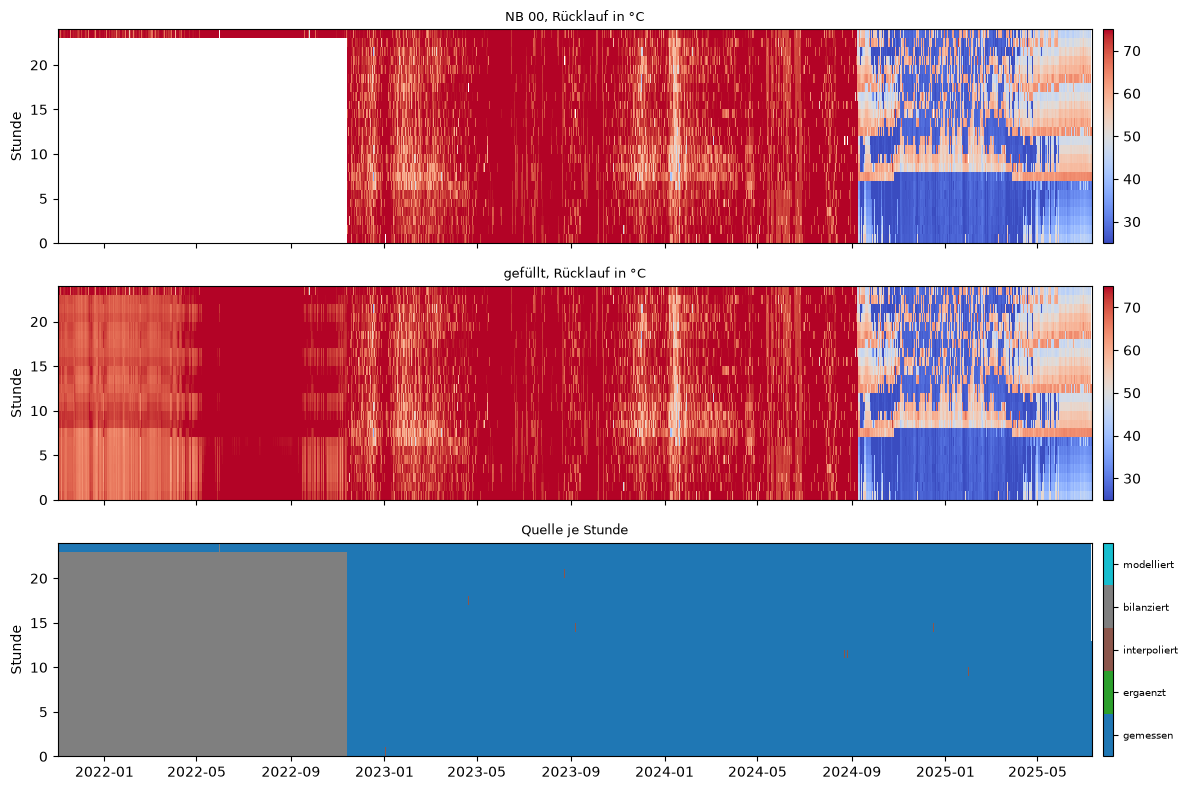

quelle
gemessen        23682
bilanziert       8649
interpoliert       11


In [10]:
ZAEHLER = 68956351
vorher = lu.auf_raster(serien[ZAEHLER])
nachher = gefuellt[ZAEHLER]
codes = {q: i for i, q in enumerate(lu.QUELLEN)}

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, (df, titel) in zip(axes[:2], [(vorher, "NB 00, Rücklauf in °C"), (nachher, "gefüllt, Rücklauf in °C")]):
    m = sb.carpetmatrix(df, kanal="rt")
    x0, x1 = mdates.date2num(m.columns[0]), mdates.date2num(m.columns[-1])
    bild = ax.imshow(m.to_numpy(float), aspect="auto", origin="lower", extent=(x0, x1, 0, 24),
                     cmap="coolwarm", vmin=25, vmax=75, interpolation="nearest")
    ax.set_title(titel, fontsize=9)
    ax.set_ylabel("Stunde")
    fig.colorbar(bild, ax=ax, pad=0.01, fraction=0.025)
q = nachher.assign(q=nachher["quelle"].map(codes))
m = sb.carpetmatrix(q, kanal="q")
cmap = plt.get_cmap("tab10", len(codes))
bild = axes[2].imshow(m.to_numpy(float), aspect="auto", origin="lower", extent=(x0, x1, 0, 24),
                      cmap=cmap, vmin=-0.5, vmax=len(codes) - 0.5, interpolation="nearest")
cb = fig.colorbar(bild, ax=axes[2], pad=0.01, fraction=0.025, ticks=range(len(codes)))
cb.ax.set_yticklabels(list(codes), fontsize=7)
axes[2].set_title("Quelle je Stunde", fontsize=9)
axes[2].set_ylabel("Stunde")
axes[2].xaxis_date()
fig.tight_layout()
plt.show()
print(nachher["quelle"].value_counts().to_string())

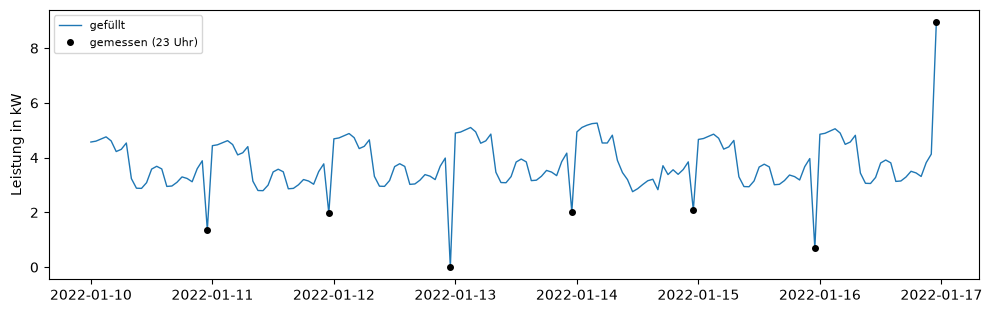

Tagesenergie aus dem gefüllten Zähler in kWh: [85.0, 89.0, 93.0, 92.0, 89.0, 96.0]


In [11]:
#eine Woche in der Tagesphase im Detail: gefüllte Stunden gegen die 23-Uhr-Werte
woche = nachher.loc["2022-01-10":"2022-01-16"]
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(woche.index, woche["power"], lw=1, label="gefüllt")
pkt = woche[woche["quelle"].isin(["gemessen", "ergaenzt"])]
ax.plot(pkt.index, pkt["power"], "o", color="black", ms=4, label="gemessen (23 Uhr)")
ax.set_ylabel("Leistung in kW")
ax.legend(fontsize=8)
plt.show()
tag = woche["energy"].resample("D").last().diff().dropna()
print("Tagesenergie aus dem gefüllten Zähler in kWh:", tag.round(1).to_list())

- Carpet geschlossen, bis November 2022 fast alles bilanziert
- Gefüllter Rücklauf unter den 23-Uhr-Werten: die Zählerstände verlangen etwa 4 K Spreizung, um 23 Uhr nur 0,7 K. Passt zum Winter 2022/23 (23 Uhr 1,05 gegen Tagesmittel 2,25 K)
- Tagesenergie stimmt per Konstruktion (10. bis 16.01.2022: 85 bis 96 kWh je Tag), der Tagesgang stammt aus dem Profil

## 6 Für das Graphennetzwerk: Dateien lesen

- Einlesen mit `lu.lade_gefuellt()`, Spalten wie NB 00
- `quelle` = Herkunft, `luecke_h` = Länge der zugehörigen Lücke (0 bei gemessenen)
- Halbwegs gesicherte Stunden: `quelle != "modelliert"` und `luecke_h <= 24`

In [12]:
probe = lu.lade_gefuellt(zaehler=[ZAEHLER])[ZAEHLER]
print(probe.columns.to_list())
streng = probe[(probe["quelle"] != "modelliert") & (probe["luecke_h"] <= 24)]
print(f"{len(probe):,} Stunden, davon {len(streng):,} mit Quelle gemessen/ergänzt/interpoliert "
      f"oder bilanziert in Lücken bis 24 h")
probe.head(3)

['flow', 'power', 'dt', 'vl', 'rt', 'energy', 'volume', 'quelle', 'luecke_h']
32,342 Stunden, davon 32,295 mit Quelle gemessen/ergänzt/interpoliert oder bilanziert in Lücken bis 24 h


,flow,power,dt,vl,rt,energy,volume,quelle,luecke_h
Timestamp,,,,,,,,,
2021-11-01 23:00:00,888.0000,0.0790,0.0000,75.6000,75.5000,17477.0000,5865.5450,gemessen,0
2021-11-02 00:00:00,899.0692,2.9001,2.8067,72.9849,70.1782,17478.4972,5866.4397,bilanziert,23
2021-11-02 01:00:00,896.0645,2.8010,2.7200,72.0381,69.3182,17481.3623,5867.3384,bilanziert,23


## Zusammenfassung & Bewertung

- Ergebnis: lückenlose Stundenreihen für alle 100 Zähler über ihre Messspanne; 30,4 % gefüllt, zwei Drittel davon aus dem Tageswert-Export, ein Drittel aus langen Ausfällen
- Belastbar: Energie- und Volumenbilanz zum Zähler, wo beide Stände vorliegen; in der Tagesphase besser als linear (71 bis 79 % der Zähler); Messwerte unverändert, Herkunft je Stunde in `quelle`
- Schwach: Tagesform bei Lücken über einen Tag nicht besser als linear, Rücklauffehler 6 bis 7 K; 72135441 und 72135443 zu 83 % gerechnet. Fürs Netzwerk Tages- und Wochensummen unbedenklich, stündlich filtern oder Herkunft als Gewicht
- Offen: gemeinsames Zeitraster über alle Zähler; Ursache der $\rho$-Abweichung bei 11 Stationen; Umgang mit der Randspanne bei 72135441 und 72135443